In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
import tensorflow as tf


from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron  # Used for simple linear
                                           # classification tasks.

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from tensorflow.keras.models import Sequential  # Sequential lets you build
                                                # a neural network layer-by-layer in Keras

from tensorflow.keras.layers import Dense      # Dense makes the final predictions
from tensorflow.keras.layers import Conv2D     # Conv2D extracts features
from tensorflow.keras.layers import Flatten    # Flatten reshapes them

from tensorflow.keras.layers import MaxPooling2D  # MaxPooling2D reduces size
from tensorflow.keras.layers import Dropout       # Dropout prevents
                                                  # overfitting

from tensorflow.keras.utils import to_categorical  # converts numeric class


In [5]:
df=pd.read_csv('mnist_train.csv')
df_test=pd.read_csv('mnist_test.csv')

In [6]:
df.head()

,label,1*1,1*2,1*3,1*4,1*5,1*6,1*7,1*8,1*9,...,28*19,28*20,28*21,28*22,28*23,28*24,28*25,28*26,28*27,28*28
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
df_test.head()

,label,1*1,1*2,1*3,1*4,1*5,1*6,1*7,1*8,1*9,...,28*19,28*20,28*21,28*22,28*23,28*24,28*25,28*26,28*27,28*28
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
x_train=df.drop("label",axis=1).values
y_train=df["label"].values
x_test=df_test.drop("label",axis=1).values
y_test=df_test["label"].values

In [10]:
x_train=x_train.astype("float32") / 255.0
x_test=x_test.astype("float32") / 255.0

In [11]:
x_train_img=x_train.reshape(-1,28,28)
x_test_img=x_test.reshape(-1,28,28)

In [12]:
x_test_img

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [13]:
y_train_cat=to_categorical(y_train,10)
y_test_cat=to_categorical(y_test,10)

In [15]:
perceptron= Sequential([
    Flatten(input_shape=(28,28)),
    Dense(10,activation="softmax")
])

In [16]:
perceptron.compile(optimizer="sgd",loss="categorical_crossentropy",metrics=["accuracy"])

In [25]:
history_percp= perceptron.fit(x_train_img,y_train_cat,epochs=15,batch_size=32,validation_data=(x_test_img,y_test_cat),verbose=1)

Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9164 - loss: 0.3022 - val_accuracy: 0.9186 - val_loss: 0.2918
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9171 - loss: 0.3000 - val_accuracy: 0.9185 - val_loss: 0.2909
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9175 - loss: 0.2981 - val_accuracy: 0.9166 - val_loss: 0.2891
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9178 - loss: 0.2963 - val_accuracy: 0.9176 - val_loss: 0.2878
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9184 - loss: 0.2947 - val_accuracy: 0.9189 - val_loss: 0.2871
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9187 - loss: 0.2932 - val_accuracy: 0.9189 - val_loss: 0.2860
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9192 - loss: 0.2917 - val_accuracy: 0.9188 - val_loss: 0.2850
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.9194 - loss: 0.2905 - 

In [26]:
acc_percp= perceptron.evaluate(x_test_img,y_test_cat,verbose=0) [1]

In [27]:
acc_percp

0.9210000038146973

In [28]:
ann= Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(10,activation="softmax")
])

In [29]:
ann.compile(optimizer="adam",loss="categorical_crossentropy",metrics=['accuracy'])

In [31]:
history_ann=ann.fit(x_train_img,y_train_cat,epochs=5,batch_size=50,validation_data=(x_test_img,y_test_cat),verbose=1)

Epoch 1/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9947 - loss: 0.0160 - val_accuracy: 0.9774 - val_loss: 0.0998
Epoch 2/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.9950 - loss: 0.0152 - val_accuracy: 0.9802 - val_loss: 0.0893
Epoch 3/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9959 - loss: 0.0125 - val_accuracy: 0.9761 - val_loss: 0.1051
Epoch 4/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9950 - loss: 0.0138 - val_accuracy: 0.9786 - val_loss: 0.1036
Epoch 5/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9959 - loss: 0.0118 - val_accuracy: 0.9798 - val_loss: 0.0945


In [34]:
acc_ann= ann.evaluate(x_test_img,y_test_cat,verbose=0) [1]

In [35]:
acc_ann

0.9797999858856201

In [36]:
x_train_cnn=x_train.reshape(-1,28,28,1)
x_test_cnn=x_test.reshape(-1,28,28,1)

In [37]:
cnn=Sequential([
    Conv2D(32, kernel_size=(3,3),activation='relu',input_shape=(28,28,1)),
    MaxPooling2D(pool_size=(2,2)),
    Conv2D(64,kernel_size=(3,3),activation='relu'),
    MaxPooling2D(pool_size=(2,2)),
    Flatten(),
    Dense(128,activation='relu'),
    Dropout(0.5),
    Dense(10,activation="softmax")
])

In [39]:
cnn.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

In [40]:
history_cnn=cnn.fit(x_train_cnn,y_train_cat,epochs=5,batch_size=50,validation_data=(x_test_cnn,y_test_cat),verbose=1)

Epoch 1/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 52s 42ms/step - accuracy: 0.9249 - loss: 0.2433 - val_accuracy: 0.9841 - val_loss: 0.0503
Epoch 2/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 49s 41ms/step - accuracy: 0.9750 - loss: 0.0870 - val_accuracy: 0.9868 - val_loss: 0.0361
Epoch 3/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 46s 39ms/step - accuracy: 0.9810 - loss: 0.0640 - val_accuracy: 0.9894 - val_loss: 0.0299
Epoch 4/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 83s 39ms/step - accuracy: 0.9849 - loss: 0.0506 - val_accuracy: 0.9915 - val_loss: 0.0242
Epoch 5/5
1200/1200 ━━━━━━━━━━━━━━━━━━━━ 46s 39ms/step - accuracy: 0.9877 - loss: 0.0408 - val_accuracy: 0.9902 - val_loss: 0.0304


In [56]:
acc_cnn = cnn.evaluate(x_test_cnn, y_test_cat, verbose=0)[1]
acc_cnn

0.9901999831199646

In [44]:
def plot_training(history, title):
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(history.history['accuracy'], label="Train")
    plt.plot(history.history['val_accuracy'], label="Val")
    plt.title(f"{title} Accuracy")
    plt.legend()

    plt.subplot(1,2,2)
    plt.plot(history.history['loss'], label="Train")
    plt.plot(history.history['val_loss'], label="Val")
    plt.title(f"{title} Loss")
    plt.legend()
    plt.show()

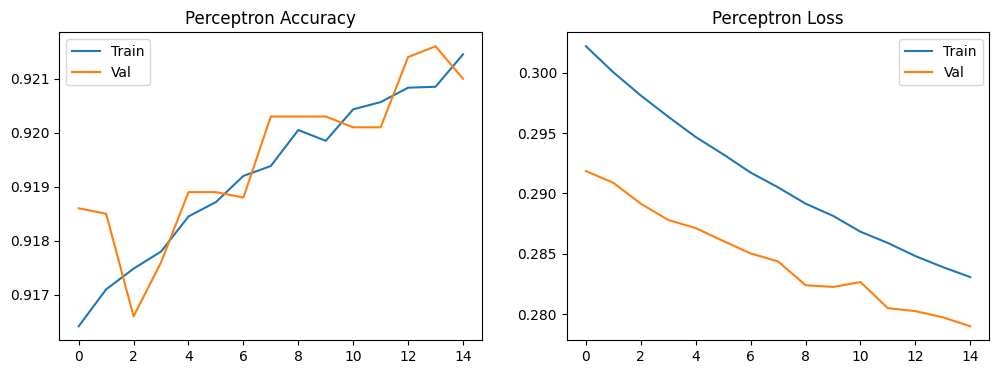

In [45]:
plot_training(history_percp, "Perceptron")

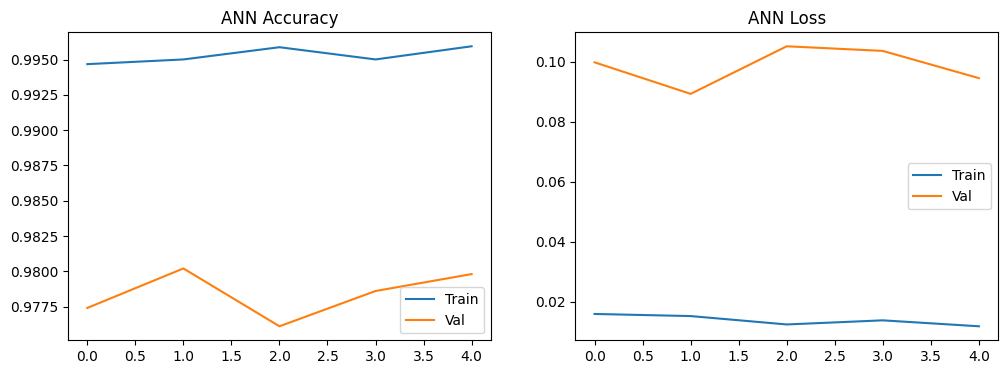

In [46]:
plot_training(history_ann, "ANN")

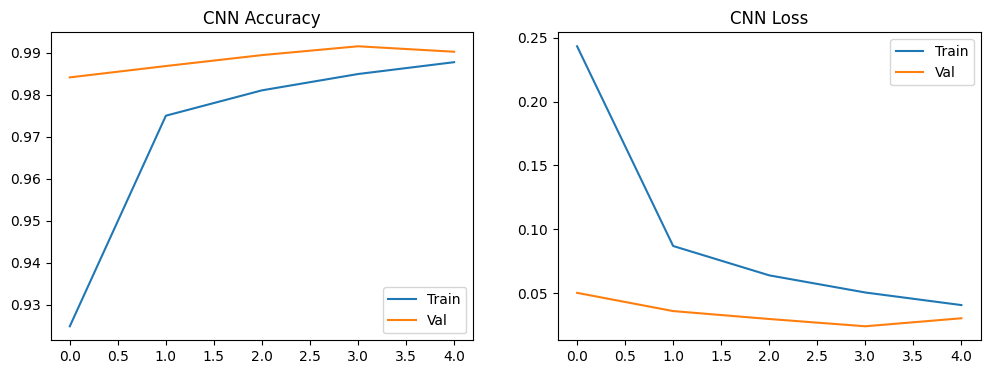

In [47]:
plot_training(history_cnn, "CNN")

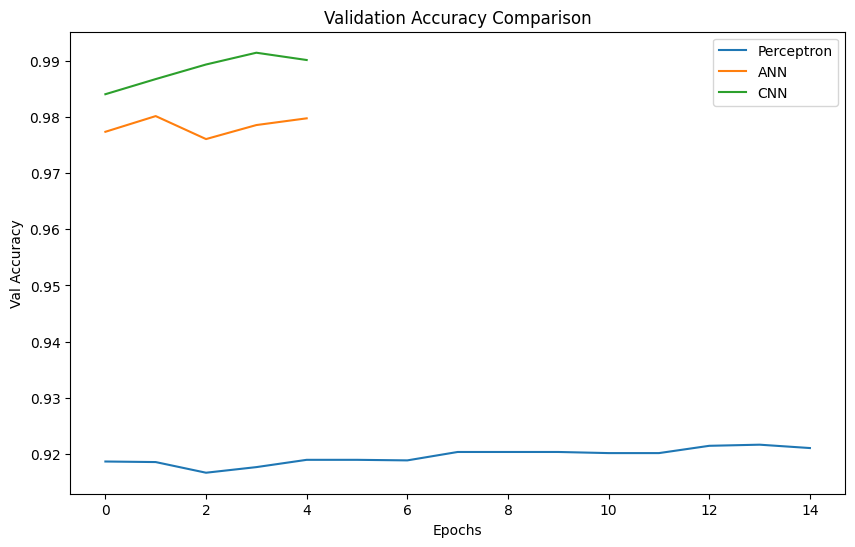

In [48]:
plt.figure(figsize=(10,6))
plt.plot(history_percp.history['val_accuracy'], label="Perceptron")
plt.plot(history_ann.history['val_accuracy'], label="ANN")
plt.plot(history_cnn.history['val_accuracy'], label="CNN")
plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Val Accuracy")
plt.legend()
plt.show()

In [49]:

def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(28, 28), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 28, 28, 1) if name == "CNN" else X[idx].reshape(1, 28, 28)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


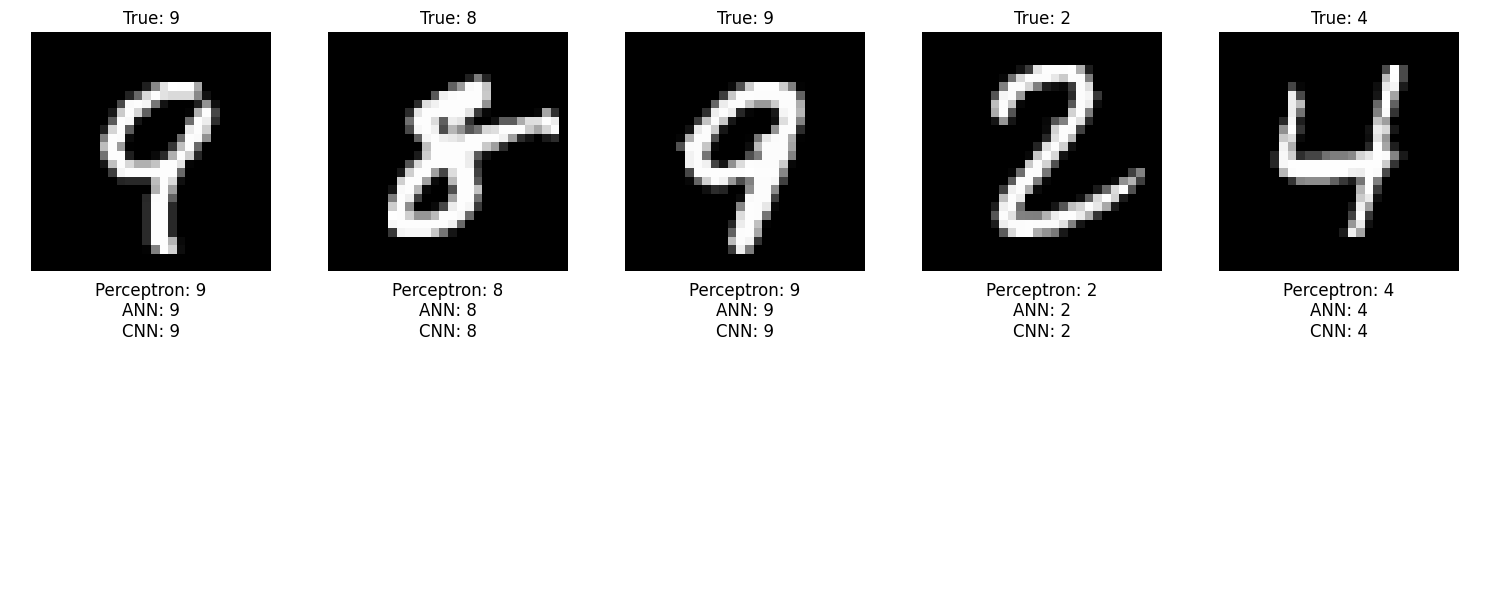

In [51]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], x_test_img, x_test_cnn, y_test, 5)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


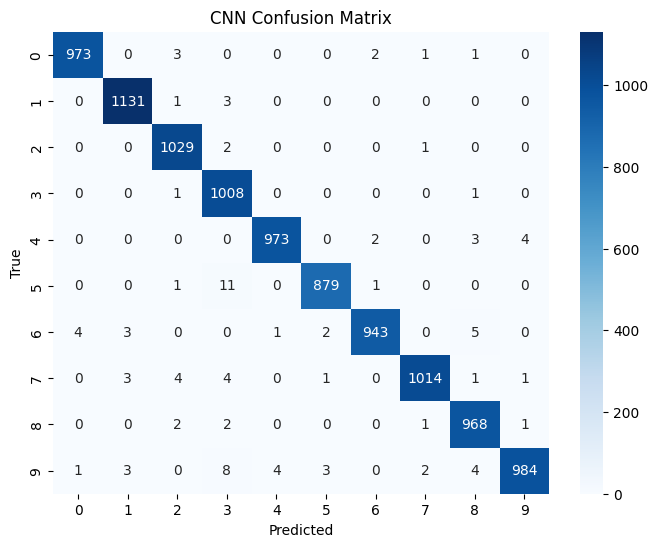

In [53]:
y_pred_cnn = np.argmax(cnn.predict(x_test_cnn), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


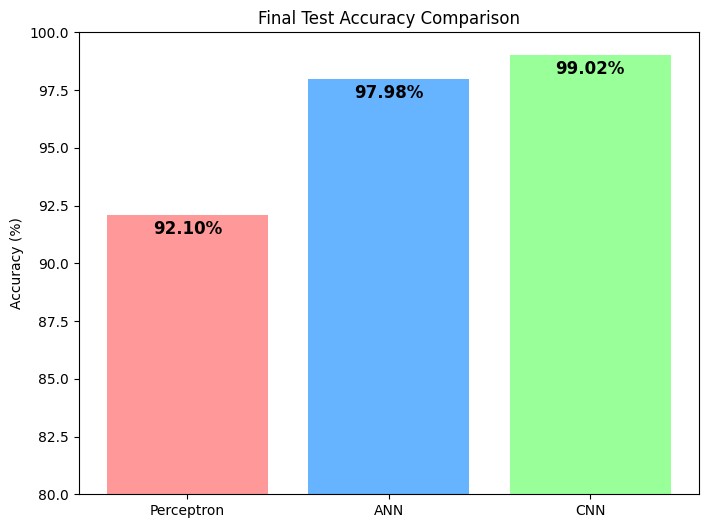

In [57]:
final_accs = [acc_percp*100, acc_ann*100, acc_cnn*100]
models = ["Perceptron", "ANN", "CNN"]

plt.figure(figsize=(8,6))
bars = plt.bar(models, final_accs, color=['#ff9999','#66b3ff','#99ff99'])
plt.title("Final Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
for bar, acc in zip(bars, final_accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-1, f"{acc:.2f}%",
             ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.ylim(80, 100)
plt.show()